# Trace Kunden – Customer Analytics & Churn-Prognose

**Geschäftsfrage.** Ein britischer Online-Großhändler für Geschenkartikel verkauft vor allem an kleine
Händler. Das Marketing will wissen: *Welche Kundengruppen haben wir, wer wird demnächst nicht mehr kaufen,
und lohnt sich eine Rückgewinnungskampagne?*

**Daten.** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) aus dem UCI Machine
Learning Repository (CC BY 4.0): alle Rechnungspositionen vom 01.12.2009 bis 09.12.2011, gut eine Million
Zeilen. Die Daten werden per Skript geladen und nicht ins Repository übernommen:
`uv run python -m trace_kunden.daten`.

**Aufbau.**
1. Bereinigung – jeder Schritt begründet und gezählt
2. Explorative Analyse – Umsatz über die Zeit, Länder, Produkte, Wochentage
3. RFM-Analyse und Segmentierung mit K-Means
4. Churn-Prognose mit zeitlich sauberem Stichtag-Design
5. Business-Teil – Maßnahmen je Segment und Wert einer Rückgewinnungskampagne

Die wiederverwendbare Logik liegt in `src/trace_kunden/` und ist mit `pytest` getestet; das Notebook ruft
sie auf und erklärt die Entscheidungen.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter
from sklearn.metrics import roc_curve

from trace_kunden import konfig as K
from trace_kunden.bereinigung import bereinigen
from trace_kunden.churn import ABGELEITET, FEATURES, churn_datensatz
from trace_kunden.daten import lade_rohdaten
from trace_kunden.diagramme import ZIEGEL_SKALA, speichern, stil_setzen, tausender
from trace_kunden.kampagne import SZENARIEN, kampagnenwert, quartalswert, top_anteil
from trace_kunden.modelle import bewerten, faustregel_score, trainieren, wichtigkeit
from trace_kunden.segmente import (
    clustern,
    k_vergleich,
    rfm_matrix,
    rfm_scores,
    rfm_tabelle,
    segment_profil,
    segmente_benennen,
)

stil_setzen()
F = K.FARBEN
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
TSD = FuncFormatter(tausender)
ERGEBNISSE: dict = {}


def pfund(x: float) -> str:
    """£-Betrag mit deutschem Tausenderpunkt."""
    return f"£{x:,.0f}".replace(",", ".")

## 0 · Daten im Überblick

In [2]:
roh = lade_rohdaten()
print(f"{len(roh):,} Zeilen · {roh['datum'].min():%d.%m.%Y} bis {roh['datum'].max():%d.%m.%Y}".replace(",", "."))
print(f"Speicher: {roh.memory_usage(deep=True).sum() / 1e6:.0f} MB")
roh.head()

1.067.371 Zeilen · 01.12.2009 bis 09.12.2011
Speicher: 99 MB


,rechnung,artikel,beschreibung,menge,datum,preis,kunde,land,blatt
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-2010


In [3]:
pd.DataFrame({
    "fehlend": roh.isna().sum(),
    "Anteil": roh.isna().mean().map("{:.1%}".format),
})

,fehlend,Anteil
rechnung,0,0.0%
artikel,0,0.0%
beschreibung,4382,0.4%
menge,0,0.0%
datum,0,0.0%
preis,0,0.0%
kunde,243007,22.8%
land,0,0.0%
blatt,0,0.0%


Auffällig auf den ersten Blick: Bei gut einem Fünftel der Zeilen fehlt die Kunden-ID, es gibt negative Mengen
(Stornos) und einzelne Positionen mit absurden Mengen. Das klären wir jetzt Schritt für Schritt.

## 1 · Bereinigung

Ziel ist eine Tabelle, die **echtes Kaufverhalten identifizierbarer Kunden** abbildet. Jede Regel steht in
`bereinigung.py`, ist getestet und zählt, wie viele Zeilen sie entfernt.

In [4]:
verkaeufe, stornos, protokoll = bereinigen(roh)
tabelle = protokoll.tabelle()
tabelle["Anteil an Rohdaten"] = (tabelle["entfernt"] / len(roh)).map("{:.1%}".format)
tabelle

,entfernt,verbleibend,begründung,Anteil an Rohdaten
schritt,,,,
Exakte Duplikate,34335,1033036,Identische Zeilen (u. a. Überlappung der beide...,3.2%
Fehlende Kunden-ID,235151,797885,Ohne Kunden-ID lässt sich der Kauf keinem Kund...,22.0%
Stornos ausgegliedert,18390,779495,Stornos sind kein Umsatz. Sie werden separat a...,1.7%
Stornierte Käufe (Ausreißer),6332,773163,Käufe mit passender Storno-Gegenbuchung haben ...,0.6%
Keine Produkte,2706,770457,"Porto, Gebühren, manuelle Korrekturen und Test...",0.3%
Menge oder Preis ≤ 0,59,770398,Gratis- oder Korrekturbuchungen ohne Storno-Ke...,0.0%


In [5]:
positiv = roh[(roh["menge"] > 0) & (roh["preis"] > 0) & ~roh["rechnung"].str.startswith("C")]
umsatz_ohne_id = (positiv.loc[positiv["kunde"].isna(), "menge"] * positiv.loc[positiv["kunde"].isna(), "preis"]).sum()
anteil_ohne_id = umsatz_ohne_id / (positiv["menge"] * positiv["preis"]).sum()
print(f"Verbleibend: {len(verkaeufe):,} Verkaufszeilen ({len(verkaeufe) / len(roh):.0%} der Rohdaten), "
      f"{verkaeufe['kunde'].nunique():,} Kunden, {pfund(verkaeufe['umsatz'].sum())} Umsatz".replace(",", "."))
print(f"Stornozeilen (für das Merkmal Storno-Quote): {len(stornos):,}".replace(",", "."))
print(f"Umsatzanteil ohne Kunden-ID: {anteil_ohne_id:.1%}")
ERGEBNISSE["bereinigung"] = {
    "roh_zeilen": len(roh), "zeilen": len(verkaeufe), "kunden": int(verkaeufe["kunde"].nunique()),
    "umsatz": round(float(verkaeufe["umsatz"].sum())), "umsatzanteil_ohne_id": round(float(anteil_ohne_id), 3),
    "schritte": protokoll.tabelle()["entfernt"].to_dict(),
}

Verbleibend: 770.398 Verkaufszeilen (72% der Rohdaten). 5.839 Kunden. £16.467.060 Umsatz
Stornozeilen (für das Merkmal Storno-Quote): 18.390
Umsatzanteil ohne Kunden-ID: 15.4%


**Entscheidungen und ihre Folgen**

- **Duplikate.** Exakt gleiche Zeilen, vor allem aus der Überlappung der beiden Excel-Blätter im Dezember 2010.
  Sie würden Umsatz doppelt zählen.
- **Fehlende Kunden-ID.** Mit Abstand der größte Schritt. Diese Käufe tragen rund 15 % zum Umsatz bei, lassen sich
  aber keinem Kunden zuordnen. Für RFM und Churn sind sie wertlos. Die Umsatzzahlen in diesem Notebook sind deshalb
  **Umsatz mit identifizierten Kunden**, nicht der Gesamtumsatz des Händlers.
- **Stornos** (Rechnungsnummer beginnt mit „C“) sind kein Umsatz. Ich werfe sie aber nicht weg: Wie oft ein Kunde
  storniert, ist ein mögliches Warnsignal und wird später ein Merkmal.
- **Stornierte Käufe als Ausreißer.** Statt einer willkürlichen Mengengrenze entferne ich Käufe, zu denen es eine
  passende Storno-Gegenbuchung gibt (gleicher Kunde, Artikel, Menge, Storno danach). Darunter die zwei extremen
  Ausreißer des Datensatzes: 80.995 bzw. 74.215 Stück, jeweils Minuten später storniert. Ein Kauf, der
  rückgängig gemacht wurde, ist kein Kaufverhalten.
- **Keine Produkte.** Porto (POST, DOT), Gebühren (BANK CHARGES, AMAZONFEE), manuelle Buchungen (M, ADJUST) und
  Testartikel. Echte Artikel haben eine fünfstellige Nummer.
- **Menge oder Preis ≤ 0** ohne Storno-Kennzeichen sind Korrektur- oder Gratisbuchungen.

**Ausreißer auf Kundenebene behalte ich bewusst.** Es gibt einige Großkunden mit sehr hohem Umsatz. Das sind
keine Fehler, sondern die wichtigsten Kunden des Händlers. Statt sie zu löschen, mildere ich ihren Einfluss
später durch eine Log-Transformation.

In [6]:
umsatz_je_kunde = verkaeufe.groupby("kunde")["umsatz"].sum()
q1, q3 = umsatz_je_kunde.quantile([0.25, 0.75])
grenze = q3 + 3 * (q3 - q1)
gross = umsatz_je_kunde > grenze
print(f"Kunden über Q3 + 3·IQR ({pfund(grenze)}): {gross.sum()} von {len(gross)} "
      f"({gross.mean():.1%}), zusammen {umsatz_je_kunde[gross].sum() / umsatz_je_kunde.sum():.0%} des Umsatzes")

Kunden über Q3 + 3·IQR (£7.817): 362 von 5839 (6.2%), zusammen 55% des Umsatzes


## 2 · Explorative Analyse

### Umsatz pro Monat

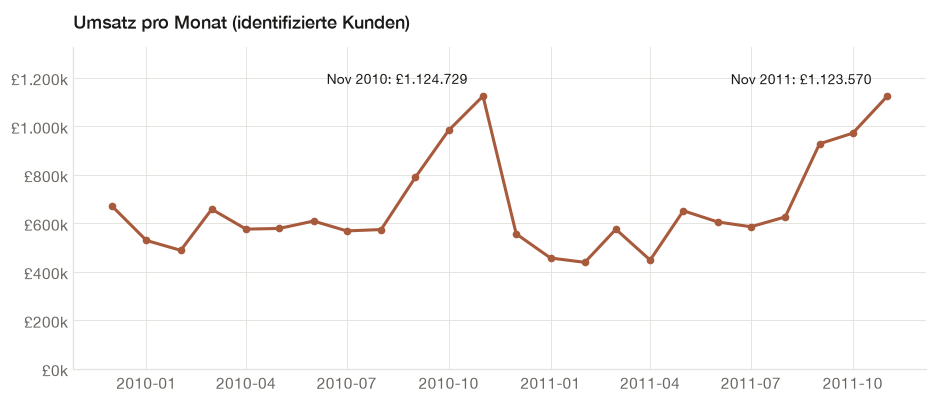

In [7]:
monat = verkaeufe.groupby(verkaeufe["datum"].dt.to_period("M"))["umsatz"].sum()
monat = monat[monat.index < pd.Period("2011-12")]  # Dezember 2011 endet am 9. → unvollständig
fig, ax = plt.subplots(figsize=(10, 3.8))
x = monat.index.to_timestamp()
ax.plot(x, monat.values / 1000, color=F["ziegel"], marker="o", markersize=4)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v:,.0f}k".replace(",", ".")))
for jahr in (2010, 2011):
    spitze = monat[monat.index.year == jahr].idxmax()
    ax.annotate(f"{spitze.strftime('%b %Y')}: {pfund(monat[spitze])}", (spitze.to_timestamp(), monat[spitze] / 1000),
                textcoords="offset points", xytext=(-10, 8), ha="right", fontsize=9, color=F["tinte"])
ax.set_title("Umsatz pro Monat (identifizierte Kunden)")
ax.set_ylim(0, monat.max() / 1000 * 1.18)
speichern(fig, "01-umsatz-monat")
plt.show()

In [8]:
jahr_vergleich = pd.DataFrame({
    "Dez 2009 – Nov 2010": monat[(monat.index >= pd.Period("2009-12")) & (monat.index <= pd.Period("2010-11"))].sum(),
    "Dez 2010 – Nov 2011": monat[(monat.index >= pd.Period("2010-12")) & (monat.index <= pd.Period("2011-11"))].sum(),
}, index=["Umsatz"])
q4_anteil = monat[monat.index.month.isin([9, 10, 11])].sum() / monat.sum()
print(jahr_vergleich.map(pfund).to_string())
print(f"Anteil September–November am Umsatz: {q4_anteil:.0%} (bei Gleichverteilung wären es 25 %)")

       Dez 2009 – Nov 2010 Dez 2010 – Nov 2011
Umsatz          £8.153.592          £7.970.597
Anteil September–November am Umsatz: 37% (bei Gleichverteilung wären es 25 %)


**Saisonalität ist das bestimmende Muster.** In beiden Jahren steigt der Umsatz ab September stark an und
erreicht im November den Höhepunkt: Die Kunden sind Händler, die sich für das Weihnachtsgeschäft eindecken.
Das ist später für die Churn-Prognose wichtig. Ob ein Kunde „im nächsten Quartal kauft“, hängt stark davon
ab, welches Quartal das ist.

### Länder und Produkte

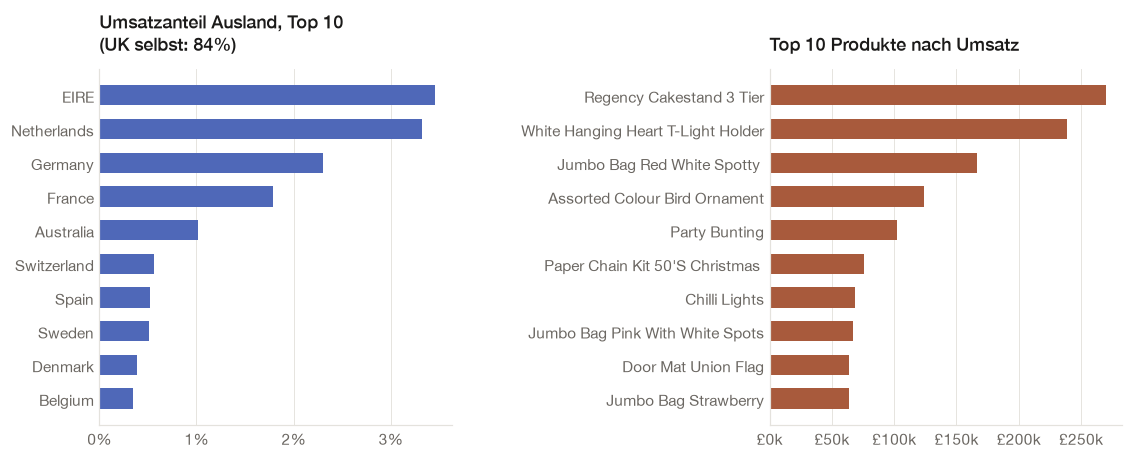

UK: 83.5% des Umsatzes · Top-Artikel: 1.6%. Top 10 zusammen: 7.5% · 4.611 verschiedene Artikel


In [9]:
land = verkaeufe.groupby("land", observed=True)["umsatz"].sum().sort_values(ascending=False)
anteil_uk = land["United Kingdom"] / land.sum()

ausland = (land.drop("United Kingdom") / land.sum()).head(10)

top = (verkaeufe.groupby("artikel").agg(umsatz=("umsatz", "sum"), beschreibung=("beschreibung", "first"))
       .nlargest(10, "umsatz"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.9})
a1.barh(ausland.index[::-1], ausland.values[::-1], color=F["blau"], height=0.6)
a1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.set_title(f"Umsatzanteil Ausland, Top 10\n(UK selbst: {anteil_uk:.0%})")
a1.grid(axis="y", visible=False)
namen = [b.title()[:36] for b in top["beschreibung"][::-1]]
a2.barh(namen, top["umsatz"][::-1] / 1000, color=F["ziegel"], height=0.6)
a2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v:,.0f}k"))
a2.set_title("Top 10 Produkte nach Umsatz")
a2.grid(axis="y", visible=False)
speichern(fig, "02-laender-produkte")
plt.show()
print(f"UK: {anteil_uk:.1%} des Umsatzes · Top-Artikel: {top['umsatz'].iat[0] / verkaeufe['umsatz'].sum():.1%}, "
      f"Top 10 zusammen: {top['umsatz'].sum() / verkaeufe['umsatz'].sum():.1%} · "
      f"{verkaeufe['artikel'].nunique():,} verschiedene Artikel".replace(",", "."))

- **Der Händler ist ein britisches Unternehmen mit Exportgeschäft.** 84 % des Umsatzes kommen aus UK, im
  Ausland vor allem Irland (EIRE, wenige sehr große Kunden), die Niederlande, Deutschland und Frankreich.
- **Das Sortiment ist breit, ohne einzelnen Bestseller.** Der stärkste Artikel (dreistöckiger Tortenständer) bringt
  1,6 % des Umsatzes, die Top 10 zusammen 7,5 %, verteilt auf über 4.600 Artikel. Für die Kundenanalyse heißt das: Nicht einzelne Produkte binden
  die Kunden, sondern das Sortiment insgesamt.

### Wann wird bestellt?

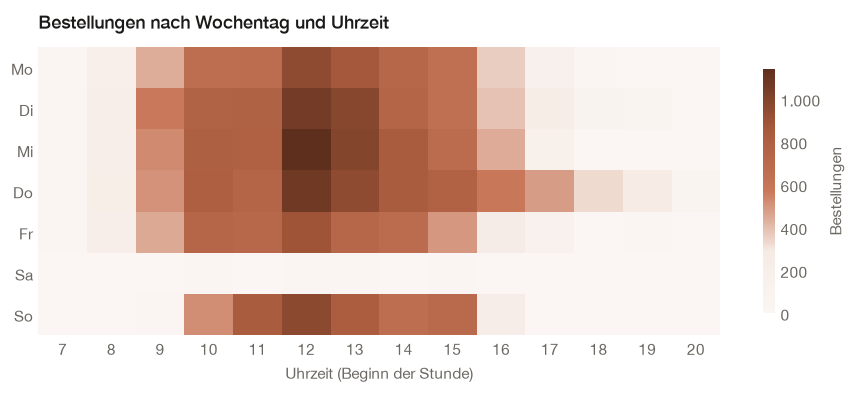

In [10]:
rechnungen = verkaeufe.drop_duplicates("rechnung")
tage = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
wh = pd.crosstab(rechnungen["datum"].dt.day_of_week, rechnungen["datum"].dt.hour).reindex(range(7), fill_value=0)
wh = wh.loc[:, 7:20]
fig, ax = plt.subplots(figsize=(10, 3.4))
bild = ax.imshow(wh.values, cmap=ZIEGEL_SKALA, aspect="auto")
ax.set_yticks(range(7), tage)
ax.set_xticks(range(len(wh.columns)), [f"{h}" for h in wh.columns])
ax.set_xlabel("Uhrzeit (Beginn der Stunde)")
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(bild, ax=ax, label="Bestellungen", shrink=0.85, format=TSD).outline.set_visible(False)
ax.set_title("Bestellungen nach Wochentag und Uhrzeit")
speichern(fig, "03-wochentag-uhrzeit")
plt.show()

Bestellt wird zu Bürozeiten von Montag bis Freitag und am Sonntag, **samstags gar nicht** (der Shop nimmt
samstags offenbar keine Bestellungen an oder verbucht sie nicht). Die Spitze liegt zwischen 10 und 15 Uhr. Das
bestätigt das Bild eines B2B-Geschäfts und ist praktisch: Kampagnen-Mails sollten werktags am Vormittag
rausgehen.

## 3 · RFM-Analyse und Segmentierung

RFM beschreibt jeden Kunden mit drei Zahlen:
- **Recency** – Tage seit dem letzten Kauf (kleiner = besser)
- **Frequency** – Anzahl Bestellungen
- **Monetary** – Umsatz insgesamt

Referenzdatum ist der Tag nach dem letzten Kauf im Datensatz (10.12.2011).

In [11]:
referenz = verkaeufe["datum"].max().normalize() + pd.Timedelta(days=1)
rfm = rfm_tabelle(verkaeufe, referenz)
rfm.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T

,count,mean,std,min,25%,50%,75%,95%,max
recency,"5,839.00",199.91,208.61,0.00,25.00,95.00,379.00,623.00,738.00
frequency,"5,839.00",6.22,12.63,1.00,1.00,3.00,7.00,20.00,369.00
monetary,"5,839.00","2,820.18","13,875.95",2.90,336.25,851.01,"2,206.48","8,977.99","579,128.64"


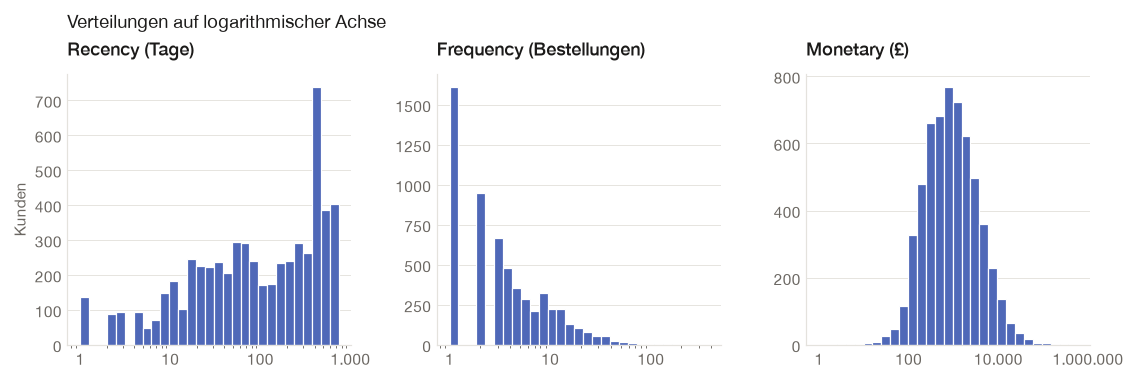

In [12]:
fig, achsen = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"wspace": 0.3})
for ax, spalte, titel in zip(achsen, ["recency", "frequency", "monetary"],
                             ["Recency (Tage)", "Frequency (Bestellungen)", "Monetary (£)"]):
    werte = rfm[spalte].clip(lower=1)
    bins = np.logspace(0, np.log10(werte.max()), 30)
    ax.hist(werte, bins=bins, color=F["blau"], edgecolor="white", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_title(titel)
    ax.xaxis.set_major_formatter(TSD)
    ax.grid(axis="x", visible=False)
achsen[0].set_ylabel("Kunden")
fig.suptitle("Verteilungen auf logarithmischer Achse", x=0.125, ha="left", y=1.06, fontsize=12)
speichern(fig, "04-rfm-verteilung")
plt.show()

Alle drei Größen sind **stark rechtsschief**: Der Median-Kunde hat 3 Bestellungen, die oberen 5 % haben über 30.
Für K-Means hat das zwei Folgen:
1. **Log-Transformation** (`log1p`), sonst bilden die wenigen Großkunden eigene Cluster und alle anderen landen
   in einem Topf.
2. **Standardisierung**, sonst dominiert Monetary (Werte bis in die Hunderttausende) jede Distanzberechnung.

Zur Einordnung zuerst die klassischen RFM-Scores (Quintile, 5 = am besten):

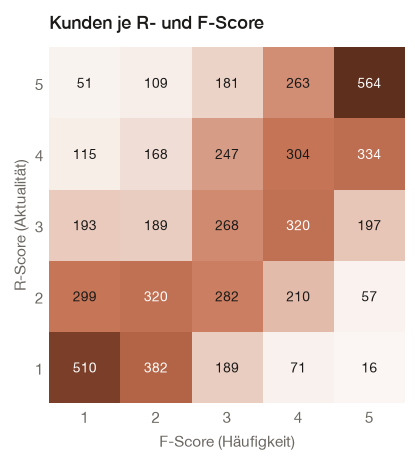

In [13]:
scores = rfm_scores(rfm)
rf_matrix = pd.crosstab(scores["R"], scores["F"]).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(5.6, 4.2))
bild = ax.imshow(rf_matrix.values, cmap=ZIEGEL_SKALA)
for (i, j), wert in np.ndenumerate(rf_matrix.values):
    ax.text(j, i, f"{wert}", ha="center", va="center", fontsize=9,
            color="white" if wert > rf_matrix.values.max() * 0.55 else F["tinte"])
ax.set_xticks(range(5), rf_matrix.columns)
ax.set_yticks(range(5), rf_matrix.index)
ax.set_xlabel("F-Score (Häufigkeit)")
ax.set_ylabel("R-Score (Aktualität)")
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Kunden je R- und F-Score")
plt.show()

Die Diagonale ist stark besetzt: Wer oft kauft, hat meist auch kürzlich gekauft. Oben rechts (R5/F5) sitzen die
besten Kunden, unten links die verlorenen Einmalkäufer. Interessant für das Marketing ist die Zone **niedriges R
bei hohem F**: Kunden, die früher oft gekauft haben, aber seit Monaten nicht mehr.

### K-Means: Wie viele Segmente?

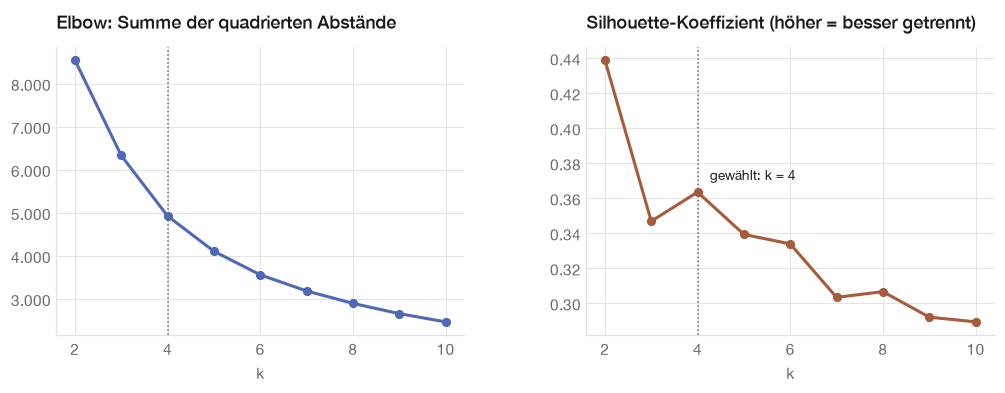

k,2,3,4,5,6,7,8,9,10
inertia,"8,544.74","6,328.13","4,923.40","4,103.75","3,557.08","3,182.43","2,893.57","2,654.92","2,464.22"
silhouette,0.44,0.35,0.36,0.34,0.33,0.30,0.31,0.29,0.29


In [14]:
x_rfm, skalierer = rfm_matrix(rfm)
k_tab = k_vergleich(x_rfm)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"wspace": 0.3})
a1.plot(k_tab.index, k_tab["inertia"], color=F["blau"], marker="o", markersize=5)
a1.set_title("Elbow: Summe der quadrierten Abstände")
a1.set_xlabel("k")
a1.yaxis.set_major_formatter(TSD)
a2.plot(k_tab.index, k_tab["silhouette"], color=F["ziegel"], marker="o", markersize=5)
a2.set_title("Silhouette-Koeffizient (höher = besser getrennt)")
a2.set_xlabel("k")
for ax in (a1, a2):
    ax.axvline(4, color=F["gedaempft"], linewidth=1, linestyle=":")
a2.annotate("gewählt: k = 4", (4, k_tab.loc[4, "silhouette"]), textcoords="offset points", xytext=(8, 8),
            fontsize=9)
speichern(fig, "05-k-wahl")
plt.show()
k_tab.T

**Wahl: k = 4.**
- Die **Silhouette** ist bei k = 2 am höchsten. Zwei Segmente („aktiv“ vs. „inaktiv“) sind aber für das Marketing
  zu grob, daraus folgt keine Maßnahme, die man nicht auch ohne Analyse kennt.
- Unter den brauchbaren Werten ab k = 3 hat **k = 4 die höchste Silhouette** (0,36 vs. 0,35 bei k = 3 und 0,34 bei
  k = 5).
- Im **Elbow-Diagramm** flacht die Kurve ab k = 4 sichtbar ab; jedes weitere Segment bringt weniger.

Ehrlich gesagt: Eine Silhouette von 0,36 heißt, dass die Segmente sich überlappen. Kunden liegen auf einem
Kontinuum und nicht in klar getrennten Gruppen. Die Segmente sind eine **nützliche Vereinfachung**, keine
Naturgesetze.

In [15]:
km = clustern(x_rfm, 4)
segment = segmente_benennen(rfm, km.labels_)
profil = segment_profil(rfm, segment).sort_values("umsatz_anteil", ascending=False)
REIHENFOLGE = list(profil.index)
SEG_FARBE = dict(zip(REIHENFOLGE, K.KATEGORIAL))
anzeige = profil.rename(columns={"kunden": "Kunden", "anteil_kunden": "Anteil Kunden",
                                 "recency_median": "Recency (Median, Tage)", "frequency_median": "Bestellungen (Median)",
                                 "monetary_median": "Umsatz (Median)", "umsatz_anteil": "Anteil Umsatz"})
anzeige.style.format({"Anteil Kunden": "{:.0%}", "Anteil Umsatz": "{:.0%}", "Umsatz (Median)": "£{:,.0f}",
                      "Recency (Median, Tage)": "{:.0f}", "Bestellungen (Median)": "{:.0f}"})

,Kunden,Anteil Kunden,"Recency (Median, Tage)",Bestellungen (Median),Umsatz (Median),Anteil Umsatz
segment,,,,,,
Top-Kunden,1168,20%,16,13,"£4,905",73%
Gefährdete Stammkunden,1469,25%,178,4,"£1,447",17%
Neue & Gelegenheitskunden,1231,21%,23,3,£715,6%
Verlorene Einmalkäufer,1971,34%,400,1,£269,4%


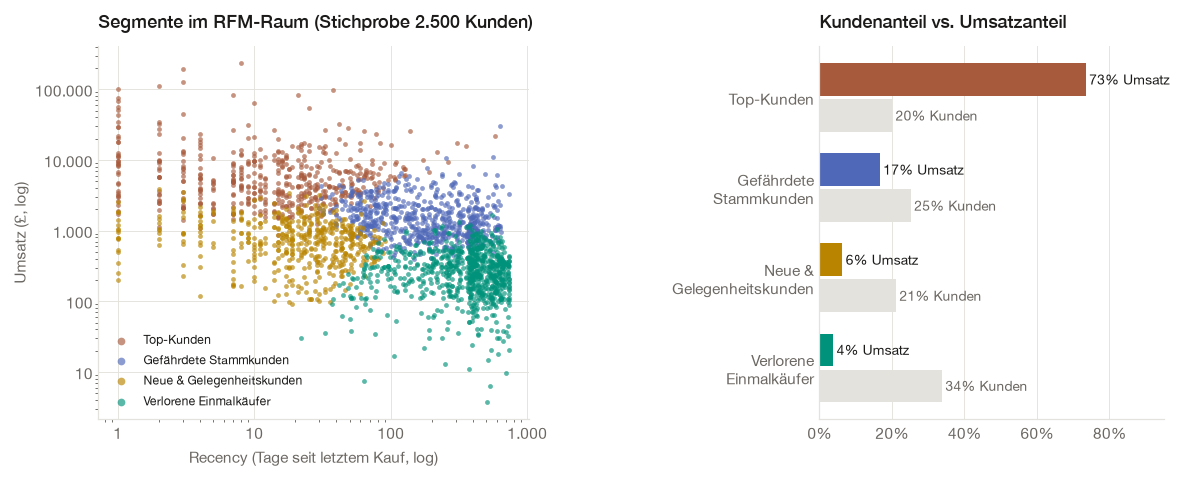

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"wspace": 0.75, "width_ratios": [1.25, 1]})
stichprobe = rfm.assign(segment=segment).sample(2500, random_state=K.SEED)
for name in REIHENFOLGE:
    d = stichprobe[stichprobe["segment"] == name]
    a1.scatter(d["recency"].clip(lower=1), d["monetary"], s=10, alpha=0.65, color=SEG_FARBE[name], label=name,
               linewidths=0)
a1.set_xscale("log")
a1.set_yscale("log")
a1.set_xlabel("Recency (Tage seit letztem Kauf, log)")
a1.set_ylabel("Umsatz (£, log)")
a1.xaxis.set_major_formatter(TSD)
a1.yaxis.set_major_formatter(TSD)
a1.legend(loc="lower left", fontsize=8, markerscale=1.6)
a1.set_title("Segmente im RFM-Raum (Stichprobe 2.500 Kunden)")

y = np.arange(len(REIHENFOLGE))
a2.barh(y + 0.2, profil["anteil_kunden"], height=0.36, color=F["linie"], label="Anteil Kunden")
a2.barh(y - 0.2, profil["umsatz_anteil"], height=0.36, color=[SEG_FARBE[n] for n in REIHENFOLGE],
        label="Anteil Umsatz")
for i, n in enumerate(REIHENFOLGE):
    a2.text(profil.loc[n, "umsatz_anteil"] + 0.01, i - 0.2, f"{profil.loc[n, 'umsatz_anteil']:.0%} Umsatz",
            va="center", fontsize=9)
    a2.text(profil.loc[n, "anteil_kunden"] + 0.01, i + 0.2, f"{profil.loc[n, 'anteil_kunden']:.0%} Kunden",
            va="center", fontsize=9, color=F["gedaempft"])
a2.set_yticks(y, [n.replace(" & ", " &\n").replace("e S", "e\nS").replace("e E", "e\nE") for n in REIHENFOLGE])
a2.invert_yaxis()
a2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a2.set_xlim(0, 0.95)
a2.grid(axis="y", visible=False)
a2.set_title("Kundenanteil vs. Umsatzanteil")
speichern(fig, "06-segmente")
plt.show()

**Die vier Segmente**

| Segment | Wer ist das? |
|---|---|
| **Top-Kunden** | Kaufen regelmäßig (Median 13 Bestellungen) und zuletzt vor gut zwei Wochen. 20 % der Kunden, **73 % des Umsatzes** – ein klassisches Pareto-Muster. |
| **Gefährdete Stammkunden** | Haben mehrfach gekauft (Median 4), aber seit rund einem halben Jahr nicht mehr. 17 % des Umsatzes. Hier liegt das größte Rückgewinnungspotenzial. |
| **Neue & Gelegenheitskunden** | Kürzlich aktiv, aber erst wenige Bestellungen. Entscheidend ist, ob aus ihnen Stammkunden werden. |
| **Verlorene Einmalkäufer** | Ein Kauf, meist über ein Jahr her. Ein Drittel der Kunden, aber nur 4 % des Umsatzes. |

Die Namen vergibt `segmente_benennen()` nach festen Regeln auf den Medianen (aktiv ≤ 90 Tage, viele
Bestellungen > Median aller Kunden). So hängen sie nicht an der zufälligen Cluster-Nummer von K-Means.

In [17]:
ERGEBNISSE["segmente"] = {
    "k": 4,
    "silhouette": {int(k): round(float(v), 3) for k, v in k_tab["silhouette"].items()},
    "profil": {n: {"kunden": int(z["kunden"]), "anteil_kunden": round(float(z["anteil_kunden"]), 3),
                   "umsatz_anteil": round(float(z["umsatz_anteil"]), 3),
                   "recency_median": float(z["recency_median"]), "frequency_median": float(z["frequency_median"]),
                   "monetary_median": round(float(z["monetary_median"]))}
               for n, z in profil.iterrows()},
}

## 4 · Churn-Prognose

### Das Stichtag-Design und warum es nötig ist

Die naheliegende, aber **falsche** Variante wäre: RFM-Werte über alle Daten berechnen, als Churn gilt „hat in den
letzten 90 Tagen nichts gekauft“, dann ein Modell trainieren. Das Modell würde nahezu perfekt aussehen, denn das
Label steckt schon in der Recency. Es würde etwas „vorhersagen“, das bereits passiert ist. Das ist **Data Leakage**.

Richtig ist es, die Situation im Einsatz nachzustellen: **An einem Stichtag** weiß das Unternehmen nur, was vorher
passiert ist.
- **Features:** ausschließlich aus Käufen *vor* dem Stichtag
- **Label:** Churn = 1, wenn der Kunde in den **90 Tagen nach** dem Stichtag nichts kauft
- **Population:** nur Kunden, die in den 12 Monaten vor dem Stichtag gekauft haben. Wer seit Jahren weg ist,
  muss man nicht vorhersagen, und er würde die Kennzahlen künstlich verbessern.

Zusätzlich teste ich **out-of-time**: Trainiert wird am Stichtag 10.06.2011, getestet am späteren Stichtag
09.09.2011. Das Label-Fenster des Trainings endet vor dem Test-Stichtag. Genau so wäre es im Betrieb: Am
09.09. kennt man die Ergebnisse des Juni-Stichtags und will die nächsten 90 Tage vorhersagen.
Ein Test auf zufällig gezogenen Kunden desselben Stichtags wäre bequemer, sagt aber nichts darüber, ob das Modell
auch im nächsten Quartal noch funktioniert.

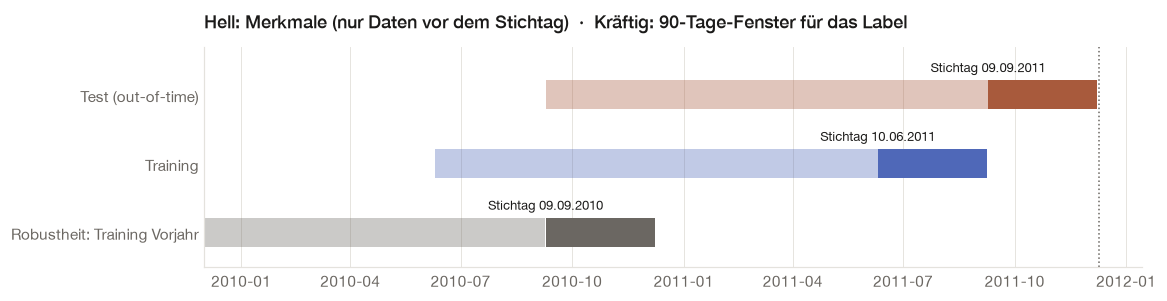

In [18]:
fenster = [
    ("Robustheit: Training Vorjahr", K.STICHTAG_TRAIN_VORJAHR, F["gedaempft"]),
    ("Training", K.STICHTAG_TRAIN, F["blau"]),
    ("Test (out-of-time)", K.STICHTAG_TEST, F["ziegel"]),
]
fig, ax = plt.subplots(figsize=(11, 2.6))
start_daten = verkaeufe["datum"].min()
for i, (name, st, farbe) in enumerate(fenster):
    beginn = max(st - pd.Timedelta(days=K.AKTIV_FENSTER_TAGE), start_daten)
    ax.barh(i, (st - beginn).days, left=beginn, height=0.42, color=farbe, alpha=0.35)
    ax.barh(i, K.CHURN_FENSTER_TAGE, left=st, height=0.42, color=farbe)
    ax.text(st, i + 0.33, f"Stichtag {st:%d.%m.%Y}", fontsize=8.5, ha="center", color=F["tinte"])
ax.set_yticks(range(len(fenster)), [f[0] for f in fenster])
ax.set_ylim(-0.5, len(fenster) - 0.3)
ax.axvline(verkaeufe["datum"].max(), color=F["gedaempft"], linewidth=1, linestyle=":")
ax.grid(axis="y", visible=False)
ax.set_title("Hell: Merkmale (nur Daten vor dem Stichtag)  ·  Kräftig: 90-Tage-Fenster für das Label")
speichern(fig, "07-stichtage")
plt.show()

In [19]:
train = churn_datensatz(verkaeufe, stornos, K.STICHTAG_TRAIN)
test = churn_datensatz(verkaeufe, stornos, K.STICHTAG_TEST)
vorjahr = churn_datensatz(verkaeufe, stornos, K.STICHTAG_TRAIN_VORJAHR)
uebersicht = pd.DataFrame({
    "Stichtag": [f"{d:%d.%m.%Y}" for d in (K.STICHTAG_TRAIN_VORJAHR, K.STICHTAG_TRAIN, K.STICHTAG_TEST)],
    "Label-Fenster": [f"{d:%d.%m.} – {d + pd.Timedelta(days=89):%d.%m.%Y}"
                      for d in (K.STICHTAG_TRAIN_VORJAHR, K.STICHTAG_TRAIN, K.STICHTAG_TEST)],
    "Kunden": [len(vorjahr), len(train), len(test)],
    "Churn-Rate": [d["churn"].mean() for d in (vorjahr, train, test)],
}, index=["Robustheit (Vorjahr)", "Training", "Test"])
uebersicht.style.format({"Churn-Rate": "{:.1%}", "Kunden": "{:,}"})

,Stichtag,Label-Fenster,Kunden,Churn-Rate
Robustheit (Vorjahr),09.09.2010,09.09. – 07.12.2010,"3,332",42.2%
Training,10.06.2011,10.06. – 07.09.2011,"4,316",64.2%
Test,09.09.2011,09.09. – 07.12.2011,"4,305",49.5%


Die Churn-Rate schwankt mit der Saison: Im Sommerfenster (Training) kaufen 64 % der aktiven Kunden nicht,
im Herbstfenster vor Weihnachten (Test) nur knapp die Hälfte. Mit ~50–64 % ist das Ungleichgewicht der Klassen
moderat. Ich gleiche es trotzdem über **Klassengewichte** aus (`class_weight="balanced"`), damit kein Modell
einfach die häufigere Klasse vorhersagt. Oversampling wie SMOTE ist bei dieser Verteilung nicht nötig.

### Merkmale

| Merkmal | Bedeutung |
|---|---|
| `recency_tage` | Tage seit dem letzten Kauf |
| `frequenz`, `umsatz_gesamt` | Bestellungen und Umsatz bisher |
| `kundendauer_tage` | Tage seit dem ersten Kauf |
| `kaeufe_90`, `kaeufe_vorher_90`, `umsatz_90` | Aktivität in den letzten 90 Tagen und in den 90 Tagen davor (Trend) |
| `aktive_monate_12` | In wie vielen der letzten 12 Monate gekauft wurde |
| `artikel_vielfalt` | Anzahl verschiedener Artikel |
| `storno_quote` | Anteil stornierter Positionen |
| `ist_uk` | Kunde aus Großbritannien |

In der ersten Iteration hatte ich zusätzlich drei Verhältnisse: Ø Warenkorb, Ø Abstand zwischen Käufen und
„überfällig“ (Recency geteilt durch den eigenen Kaufrhythmus). Warum sie wieder rausgeflogen sind, steht
unten bei der Merkmalswichtigkeit.

Ein Test in `tests/test_churn.py` prüft die wichtigste Eigenschaft: Wenn man alle Daten ab dem Stichtag
manipuliert, ändern sich die Features **nicht**.

### Modelle

- **Faustregel (ohne ML):** Risiko = Tage seit letztem Kauf. So würde ein Marketing-Team ohne Modell auswählen.
- **Logistic Regression** (Baseline-Modell): Merkmale log-transformiert und standardisiert.
- **Random Forest** und **HistGradientBoosting**: Baumverfahren, die Wechselwirkungen und Nichtlinearitäten
  von selbst lernen.

Die Hyperparameter wähle ich per 5-facher Kreuzvalidierung **nur auf dem Trainings-Stichtag**. Der Test-Stichtag
wird erst ganz am Ende einmal angefasst.

In [20]:
modelle = trainieren(train[FEATURES], train["churn"])
scores_test = {"Faustregel (Recency)": faustregel_score(test)}
for name, suche in modelle.items():
    scores_test[name] = suche.predict_proba(test[FEATURES])[:, 1]

zeilen = []
for name, sc in scores_test.items():
    b = bewerten(test["churn"], sc)
    zeilen.append({"Modell": name,
                   "CV ROC-AUC (Training)": modelle[name].best_score_ if name in modelle else np.nan,
                   "ROC-AUC": b.roc_auc, "PR-AUC": b.pr_auc, "Precision": b.precision, "Recall": b.recall,
                   "F1": b.f1, "Precision Top 20 %": b.precision_top20})
ergebnis = pd.DataFrame(zeilen).set_index("Modell")
print("Gewählte Hyperparameter:", {n: s.best_params_ for n, s in modelle.items()})
print(f"Churn-Rate im Test (= Precision bei zufälliger Auswahl): {test['churn'].mean():.1%}")
ergebnis.style.format("{:.3f}", na_rep="–").highlight_max(subset=["ROC-AUC", "PR-AUC", "F1", "Precision Top 20 %"],
                                                          props="font-weight: bold")

Gewählte Hyperparameter: {'Logistic Regression': {'logisticregression__C': 1.0}, 'Random Forest': {'max_depth': 6, 'min_samples_leaf': 20}, 'HistGradientBoosting': {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 150}}
Churn-Rate im Test (= Precision bei zufälliger Auswahl): 49.5%


,CV ROC-AUC (Training),ROC-AUC,PR-AUC,Precision,Recall,F1,Precision Top 20 %
Modell,,,,,,,
Faustregel (Recency),–,0.706,0.659,0.693,0.493,0.576,0.706
Logistic Regression,0.806,0.766,0.728,0.661,0.791,0.720,0.764
Random Forest,0.809,0.766,0.726,0.658,0.814,0.728,0.765
HistGradientBoosting,0.808,0.765,0.715,0.662,0.814,0.730,0.756


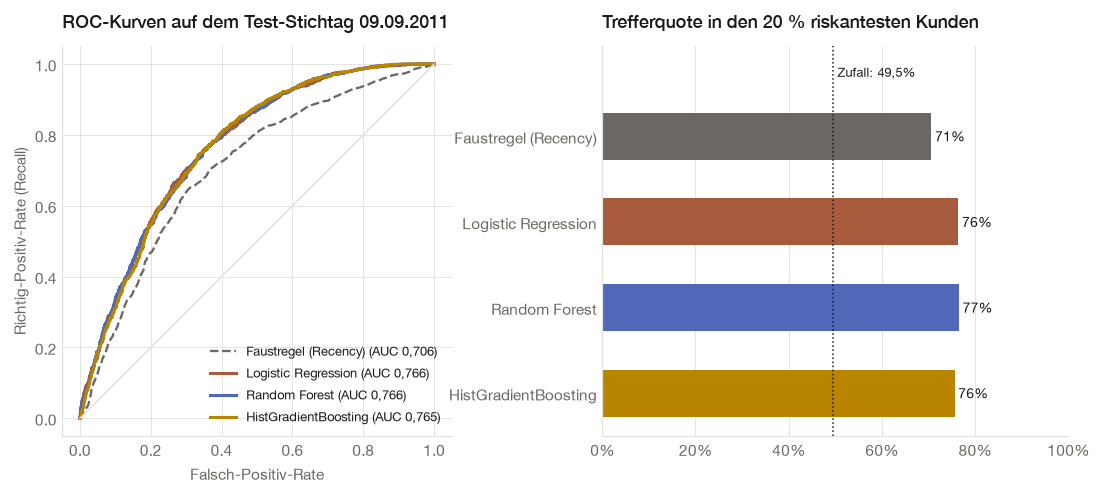

In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.3, "width_ratios": [1, 1.1]})
stil = {"Faustregel (Recency)": (F["gedaempft"], "--"), "Logistic Regression": (F["ziegel"], "-"),
        "Random Forest": (F["blau"], "-"), "HistGradientBoosting": (F["gold"], "-")}
for name, sc in scores_test.items():
    fpr, tpr, _ = roc_curve(test["churn"], sc)
    farbe, linie = stil[name]
    a1.plot(fpr, tpr, color=farbe, linestyle=linie, linewidth=2 if linie == "-" else 1.5,
            label=f"{name} (AUC {ergebnis.loc[name, 'ROC-AUC']:.3f})".replace(".", ","))
a1.plot([0, 1], [0, 1], color=F["linie"], linewidth=1)
a1.set_xlabel("Falsch-Positiv-Rate")
a1.set_ylabel("Richtig-Positiv-Rate (Recall)")
a1.set_title("ROC-Kurven auf dem Test-Stichtag 09.09.2011")
a1.legend(loc="lower right", fontsize=8.5)
a1.set_aspect("equal")

namen = list(ergebnis.index)
ypos = np.arange(len(namen))
a2.barh(ypos, ergebnis["Precision Top 20 %"], color=[stil[n][0] for n in namen], height=0.55)
a2.axvline(test["churn"].mean(), color=F["tinte"], linewidth=1, linestyle=":")
a2.text(test["churn"].mean() + 0.01, -0.75, f"Zufall: {test['churn'].mean():.1%}".replace(".", ","), fontsize=8.5,
        va="center")
for i, n in enumerate(namen):
    a2.text(ergebnis.loc[n, "Precision Top 20 %"] + 0.008, i, f"{ergebnis.loc[n, 'Precision Top 20 %']:.0%}",
            va="center", fontsize=9)
a2.set_yticks(ypos, namen)
a2.set_ylim(len(namen) - 0.5, -1.05)
a2.set_xlim(0, 1)
a2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a2.grid(axis="y", visible=False)
a2.set_title("Trefferquote in den 20 % riskantesten Kunden")
speichern(fig, "08-modellvergleich")
plt.show()

**Was die Zahlen sagen**

- **Alle drei Modelle sind praktisch gleich gut** (ROC-AUC 0,77). Random Forest und Gradient Boosting bringen
  gegenüber der Logistic Regression **nichts**. Der Zusammenhang ist offenbar weitgehend monoton („länger nicht
  gekauft, seltener gekauft → eher weg“), dafür braucht es keine komplexen Wechselwirkungen.
- **Gegenüber der Faustregel lohnt sich das Modell:** ROC-AUC 0,71 → 0,77. In den 20 % riskantesten Kunden
  liegt die Trefferquote bei 76 % statt 71 % (Zufall: knapp 50 %). Für eine Kampagne heißt das: weniger
  Streuverluste.
- **Out-of-time verliert jedes Modell Leistung:** In der Kreuzvalidierung auf dem Trainings-Stichtag lag die
  ROC-AUC bei 0,81, auf dem späteren Test-Stichtag bei 0,77. Das ist der ehrliche Preis dafür, dass sich das
  Kaufverhalten mit der Saison ändert. Ein zufälliger Split hätte diese Lücke versteckt.

**Empfehlung: Logistic Regression.** Gleich gut, schneller, stabiler und erklärbar: Jeder Koeffizient sagt, in
welche Richtung ein Merkmal wirkt. Für eine Marketing-Abteilung, die verstehen will, *warum* ein Kunde auf der
Liste steht, ist das ein echter Vorteil.

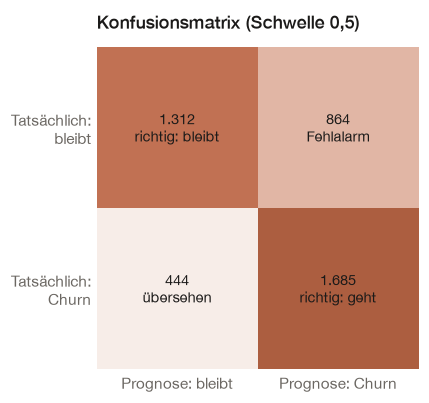

In [22]:
bestes = modelle["Logistic Regression"].best_estimator_
b = bewerten(test["churn"], scores_test["Logistic Regression"])
fig, ax = plt.subplots(figsize=(4.4, 3.8))
km_werte = b.konfusion
ax.imshow(km_werte, cmap=ZIEGEL_SKALA, vmin=0, vmax=km_werte.max() * 1.4)
beschriftung = [["richtig: bleibt", "Fehlalarm"], ["übersehen", "richtig: geht"]]
for (i, j), wert in np.ndenumerate(km_werte):
    ax.text(j, i, f"{wert:,}".replace(",", ".") + f"\n{beschriftung[i][j]}", ha="center", va="center",
            fontsize=9.5, color=F["tinte"])
ax.set_xticks([0, 1], ["Prognose: bleibt", "Prognose: Churn"])
ax.set_yticks([0, 1], ["Tatsächlich:\nbleibt", "Tatsächlich:\nChurn"])
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Konfusionsmatrix (Schwelle 0,5)")
speichern(fig, "09-konfusion")
plt.show()

Bei der Standard-Schwelle 0,5 findet das Modell **79 % der Abwanderer** (Recall), jede dritte Warnung ist aber
ein Fehlalarm (Precision 66 %). Das Modell warnt etwas zu oft. Der Grund ist die Saison: Es hat im Sommer gelernt,
als 64 % abwanderten, und erwartet diese Quote auch im Herbst, wo es nur 50 % sind. Die Rangfolge der Kunden
(ROC-AUC) ist davon kaum betroffen, die absoluten Wahrscheinlichkeiten schon. Für die Kampagne arbeite ich
deshalb mit der **Rangfolge** (die riskantesten X %) statt mit einer festen Schwelle.

### Welche Merkmale zählen?

**Permutation Importance** auf dem Test-Stichtag: Wie stark sinkt die ROC-AUC, wenn man ein Merkmal zufällig
durchmischt? Das ist modellunabhängig und misst auf ungesehenen Daten.

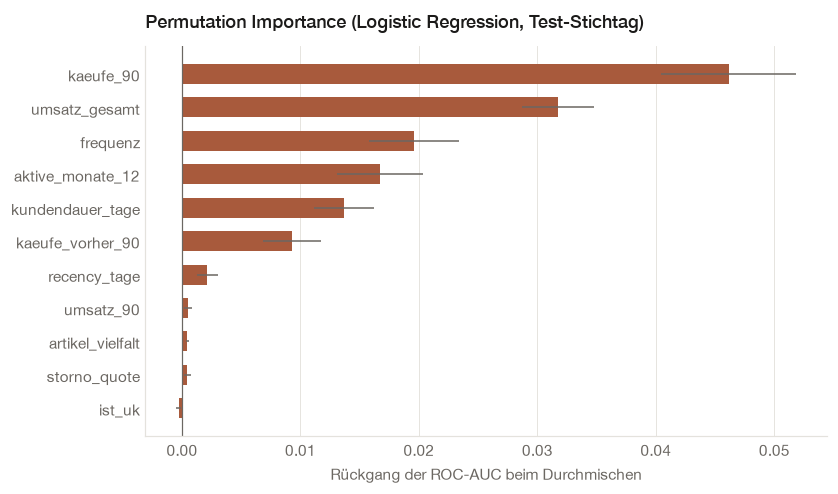

,Permutation Importance,Koeffizient (standardisiert)
kaeufe_90,0.05,-0.61
umsatz_gesamt,0.03,-0.44
frequenz,0.02,-0.34
aktive_monate_12,0.02,-0.31
kundendauer_tage,0.01,0.33
kaeufe_vorher_90,0.01,-0.26
recency_tage,0.00,-0.12
umsatz_90,0.00,0.04
artikel_vielfalt,0.00,-0.02
storno_quote,0.00,0.03


In [23]:
imp = wichtigkeit(bestes, test[FEATURES], test["churn"])
koef = pd.Series(bestes.named_steps["logisticregression"].coef_[0], index=FEATURES)
fig, ax = plt.subplots(figsize=(8, 4.6))
imp_s = imp.iloc[::-1]
ax.barh(imp_s.index, imp_s["mittel"], xerr=imp_s["std"], color=F["ziegel"], height=0.6,
        error_kw={"ecolor": F["gedaempft"], "elinewidth": 1, "capsize": 0})
ax.axvline(0, color=F["gedaempft"], linewidth=0.8)
ax.set_xlabel("Rückgang der ROC-AUC beim Durchmischen")
ax.grid(axis="y", visible=False)
ax.set_title("Permutation Importance (Logistic Regression, Test-Stichtag)")
speichern(fig, "10-wichtigkeit")
plt.show()
pd.DataFrame({"Permutation Importance": imp["mittel"], "Koeffizient (standardisiert)": koef.reindex(imp.index)})

- **Jüngste Aktivität und Kundenbindung dominieren:** Käufe in den letzten 90 Tagen, Umsatz, Bestellungen und die
  Zahl aktiver Monate. Alle haben **negative** Koeffizienten: Mehr Aktivität heißt weniger Risiko.
- **Recency wirkt im Modell kaum, obwohl sie allein gut trennt** (die Faustregel erreicht 0,71). Die Information
  steckt schon in „Käufe in den letzten 90 Tagen“: Wer dort eine 0 hat, hat zwangsläufig eine hohe Recency.
  Das Modell braucht Recency dann kaum noch zusätzlich.
- **Kundendauer wirkt positiv** (längere Kundendauer → mehr Risiko). Das klingt paradox, gilt aber *bei gleicher
  Aktivität*: Wer schon zwei Jahre Kunde ist und trotzdem nur wenige Bestellungen hat, kauft offenbar seltener als
  früher.
- **Vorsicht bei korrelierten Merkmalen** (Frequenz, aktive Monate, Umsatz). Durchmischt man eines, springen die
  anderen ein. Die Permutation Importance unterschätzt deshalb einzelne Merkmale einer korrelierten Gruppe.
- **Kaum Beitrag:** Land, Storno-Quote und Sortimentsbreite. Ein schlankeres Modell mit fünf Merkmalen wäre
  vermutlich fast genauso gut. Das wäre ein sinnvoller nächster Schritt für den Betrieb.

### Iteration: Warum 11 und nicht 14 Merkmale?

Die erste Version hatte drei zusätzliche Verhältnis-Merkmale. Die Güte war praktisch gleich, aber die
Logistic Regression lieferte **unplausible Gewichte**: Recency wirkte *negativ* (länger nicht gekauft → weniger
Risiko?), und „Umsatz gesamt“ hatte eine riesige Permutation Importance. Grund: Nach der Log-Transformation ist
log(Warenkorb) = log(Umsatz) − log(Frequenz) eine exakte Linearkombination. Das Modell kann das Gewicht beliebig
zwischen diesen Merkmalen hin- und herschieben (**Multikollinearität**). Vorhersagen bleiben gut, Erklärungen
werden wertlos.

In [24]:
lr_alt = trainieren(train[FEATURES + ABGELEITET], train["churn"])["Logistic Regression"].best_estimator_
lr_alt_score = lr_alt.predict_proba(test[FEATURES + ABGELEITET])[:, 1]
imp_alt = wichtigkeit(lr_alt, test[FEATURES + ABGELEITET], test["churn"], wiederholungen=5)
koef_alt = pd.Series(lr_alt.named_steps["logisticregression"].coef_[0], index=FEATURES + ABGELEITET)
iteration = pd.DataFrame({
    "ROC-AUC (Test)": [bewerten(test["churn"], lr_alt_score).roc_auc, ergebnis.loc["Logistic Regression", "ROC-AUC"]],
    "Koeffizient recency_tage": [koef_alt["recency_tage"], koef["recency_tage"]],
    "Koeffizient umsatz_gesamt": [koef_alt["umsatz_gesamt"], koef["umsatz_gesamt"]],
    "größte Permutation Importance": [f"{imp_alt.index[0]} ({imp_alt['mittel'].iat[0]:.3f})",
                                      f"{imp.index[0]} ({imp['mittel'].iat[0]:.3f})"],
}, index=["Iteration 1: 14 Merkmale", "Final: 11 Merkmale"])
iteration.style.format({"ROC-AUC (Test)": "{:.3f}", "Koeffizient recency_tage": "{:+.2f}",
                        "Koeffizient umsatz_gesamt": "{:+.2f}"})

,ROC-AUC (Test),Koeffizient recency_tage,Koeffizient umsatz_gesamt,größte Permutation Importance
Iteration 1: 14 Merkmale,0.768,-0.60,-1.76,umsatz_gesamt (0.254)
Final: 11 Merkmale,0.766,-0.12,-0.44,kaeufe_90 (0.046)


Ohne die drei abgeleiteten Merkmale bleibt die Güte gleich (0,768 → 0,766), und die Gewichte lassen sich wieder
lesen. Für
Random Forest und Gradient Boosting wäre die Kollinearität kein Problem. Da sie aber auch mit 14 Merkmalen nicht
besser waren, nehme ich für alle Modelle den schlankeren Satz.

### Robustheit: Was, wenn ich im selben Saisonfenster ein Jahr früher trainiere?

In [25]:
modelle_vj = trainieren(vorjahr[FEATURES], vorjahr["churn"])
robust = pd.DataFrame({
    "Training 10.06.2011 (Sommer)": {n: bewerten(test["churn"], modelle[n].predict_proba(test[FEATURES])[:, 1]).roc_auc
                                     for n in modelle},
    "Training 09.09.2010 (gleiche Saison)": {
        n: bewerten(test["churn"], modelle_vj[n].predict_proba(test[FEATURES])[:, 1]).roc_auc for n in modelle_vj},
})
robust.style.format("{:.3f}")

,Training 10.06.2011 (Sommer),Training 09.09.2010 (gleiche Saison)
Logistic Regression,0.766,0.768
Random Forest,0.766,0.747
HistGradientBoosting,0.765,0.745


Training im gleichen Herbstfenster ein Jahr früher hilft **nicht**: Die Logistic Regression erreicht wieder 0,77,
die Baumverfahren werden sogar schlechter (weniger Historie, nur 9 Monate vor dem Stichtag 2010). Die
Logistic Regression ist damit auch das **robustere** Modell. Für den Betrieb heißt das: regelmäßig mit dem
jüngsten abgeschlossenen Stichtag neu trainieren.

In [26]:
ERGEBNISSE["churn"] = {
    "stichtage": {"train": str(K.STICHTAG_TRAIN.date()), "test": str(K.STICHTAG_TEST.date()),
                  "vorjahr": str(K.STICHTAG_TRAIN_VORJAHR.date())},
    "population": {"train": len(train), "test": len(test), "vorjahr": len(vorjahr)},
    "churn_rate": {"train": round(float(train["churn"].mean()), 3), "test": round(float(test["churn"].mean()), 3),
                   "vorjahr": round(float(vorjahr["churn"].mean()), 3)},
    "test": {n: {k: round(float(v), 3) for k, v in z.items() if not pd.isna(v)}
             for n, z in ergebnis.to_dict("index").items()},
    "hyperparameter": {n: {k: (v if not isinstance(v, float) else round(v, 3)) for k, v in s.best_params_.items()}
                       for n, s in modelle.items()},
    "konfusion_lr": b.konfusion.tolist(),
    "robustheit_vorjahr_roc_auc": {n: round(float(v), 3) for n, v in robust.iloc[:, 1].items()},
    "permutation_importance_top5": {n: round(float(v), 4) for n, v in imp["mittel"].head(5).items()},
    "iteration_14_merkmale_roc_auc": round(float(bewerten(test["churn"], lr_alt_score).roc_auc), 3),
}

## 5 · Business-Teil

### Churn-Risiko je Segment

Für die Maßnahmen verbinde ich beide Teile: Jeder Kunde der Test-Population bekommt sein Segment **zum
Stichtag 09.09.2011** (gleiche Skalierung und Clusterzentren wie oben, aber RFM nur aus Daten vor dem Stichtag)
und sein Churn-Risiko aus dem Modell.

In [27]:
rfm_st = rfm_tabelle(verkaeufe, K.STICHTAG_TEST).reindex(test.index)
x_st = skalierer.transform(np.log1p(rfm_st[["recency", "frequency", "monetary"]].to_numpy(dtype=float)))
seg_st = segmente_benennen(rfm, km.labels_).groupby(km.labels_).first()  # Cluster-Nr. → Name
test_b = test.assign(segment=seg_st.reindex(km.predict(x_st)).to_numpy(),
                     risiko=scores_test["Logistic Regression"],
                     wert_quartal=quartalswert(verkaeufe, test.index, K.STICHTAG_TEST))
seg_risiko = test_b.groupby("segment").agg(
    kunden=("churn", "size"), churn_tatsaechlich=("churn", "mean"), risiko_modell=("risiko", "mean"),
    wert_quartal_median=("wert_quartal", "median"), wert_quartal_summe=("wert_quartal", "sum"),
).reindex(REIHENFOLGE)
seg_risiko.style.format({"churn_tatsaechlich": "{:.0%}", "risiko_modell": "{:.0%}",
                         "wert_quartal_median": "£{:,.0f}", "wert_quartal_summe": "£{:,.0f}"})

,kunden,churn_tatsaechlich,risiko_modell,wert_quartal_median,wert_quartal_summe
segment,,,,,
Top-Kunden,856,15%,14%,£794,"£1,350,196"
Gefährdete Stammkunden,1486,51%,56%,£202,"£406,393"
Neue & Gelegenheitskunden,678,44%,46%,£134,"£116,351"
Verlorene Einmalkäufer,1285,74%,80%,£60,"£94,720"


### Handlungsempfehlungen je Segment

| Segment | Ziel | Maßnahmen | Erfolg messen an |
|---|---|---|---|
| **Top-Kunden** | Halten und ausbauen | Persönlicher Ansprechpartner, frühzeitiger Zugang zur Weihnachtskollektion, Mengenrabatte statt Gutscheinen (keine Marge verschenken) | Bestellfrequenz, Umsatz je Kunde, Churn-Rate < 15 % |
| **Neue & Gelegenheitskunden** | Zweiten und dritten Kauf auslösen | Onboarding-Mailstrecke nach dem ersten Kauf, Sortimentsempfehlungen auf Basis des ersten Warenkorbs, Erinnerung im persönlichen Kaufrhythmus | Anteil mit 2. Bestellung innerhalb von 90 Tagen |
| **Gefährdete Stammkunden** | Zurückgewinnen | Gezielte Rückgewinnungskampagne mit Modell-Score (siehe unten), Rückfrage nach Gründen (Preis? Sortiment? Wettbewerber?), zeitlich begrenzter Gutschein vor der Saison im September | Reaktivierungsquote ggü. Kontrollgruppe |
| **Verlorene Einmalkäufer** | Kosten niedrig halten | Nur günstige Kanäle (Newsletter), keine teuren Gutscheine; einmal jährlich Saison-Mailing | Kosten je Reaktivierung |

Die wichtigste Erkenntnis für das Marketing: **Timing schlägt Rabatt.** Die Kunden sind Händler mit klarem
Saisonrhythmus. Eine Rückgewinnung im Juli erreicht sie, wenn sie ohnehin nicht einkaufen; Anfang September,
vor dem Weihnachtsgeschäft, ist das Zeitfenster.

### Was ist eine Rückgewinnungskampagne wert?

**Annahmen** (in `kampagne.py` an einer Stelle; vorsichtig gewählt und als Szenarien variiert):

| Annahme | pessimistisch | realistisch | optimistisch |
|---|---:|---:|---:|
| Erfolgsquote: Anteil echter Abwanderer, die durch die Kampagne doch kaufen | 5 % | 10 % | 15 % |
| Kosten je angeschriebenem Kunden (Gutschein, Versand, inkl. Mitnahmeeffekt) | £8 | £5 | £3 |
| Deckungsbeitrag (Marge) auf den zurückgewonnenen Umsatz | 20 % | 25 % | 30 % |
| Wie lange der zurückgewonnene Kunde kauft | 1 Quartal | 1 Quartal | 2 Quartale |

Wert eines zurückgewonnenen Kunden = sein Ø Quartalsumsatz der letzten 12 Monate × Marge × Quartale.
Die Rechnung läuft **rückblickend** auf dem Test-Stichtag: Wir wissen, wer tatsächlich abgewandert ist, und
können so ehrlich zählen, wie viele Abwanderer jede Auswahl trifft.

**Vier Auswahlstrategien**, jeweils 20 % der aktiven Kunden (861 Kunden):
1. **Zufällig** – Gießkanne
2. **Faustregel** – die 20 % mit der längsten Zeit seit dem letzten Kauf
3. **Modell** – die 20 % mit dem höchsten Churn-Risiko
4. **Modell × Kundenwert** – die 20 % mit dem höchsten *erwarteten Verlust* (Risiko × Quartalswert)

In [28]:
rng = np.random.default_rng(K.SEED)
churn_test = test_b["churn"].to_numpy()
wert = test_b["wert_quartal"].to_numpy()
strategien = {
    "Zufällig": top_anteil(rng.random(len(test_b)), 0.2),
    "Faustregel (Recency)": top_anteil(faustregel_score(test_b), 0.2),
    "Modell (Risiko)": top_anteil(test_b["risiko"].to_numpy(), 0.2),
    "Modell × Kundenwert": top_anteil(test_b["risiko"].to_numpy() * wert, 0.2),
}
zeilen = []
for s_name, maske in strategien.items():
    for a in SZENARIEN:
        r = kampagnenwert(maske, churn_test, wert, a)
        zeilen.append({"Strategie": s_name, "Szenario": a.name, **r,
                       "erreichter_wert": float(wert[maske & churn_test.astype(bool)].sum())})
kampagne = pd.DataFrame(zeilen)
pivot = kampagne.pivot(index="Strategie", columns="Szenario", values="ergebnis")[
    ["pessimistisch", "realistisch", "optimistisch"]].reindex(list(strategien))
basis = kampagne[kampagne["Szenario"] == "realistisch"].set_index("Strategie")[
    ["angeschrieben", "davon_abwanderer", "trefferquote", "erreichter_wert", "kosten"]].reindex(list(strategien))
a_real = next(a for a in SZENARIEN if a.name == "realistisch")
# Ab welcher Erfolgsquote trägt sich die Kampagne? Kosten / (erreichter Quartalswert × Marge × Quartale)
basis["break_even_quote"] = basis["kosten"] / (basis["erreichter_wert"] * a_real.marge * a_real.quartale)
display(basis.style.format({"trefferquote": "{:.0%}", "erreichter_wert": "£{:,.0f}", "kosten": "£{:,.0f}",
                           "break_even_quote": "{:.1%}"}))
pivot.style.format(lambda v: ("−" if v < 0 else "") + f"£{abs(v):,.0f}").set_caption("Ergebnis der Kampagne (Nutzen − Kosten) in £")

,angeschrieben,davon_abwanderer,trefferquote,erreichter_wert,kosten,break_even_quote
Strategie,,,,,,
Zufällig,861,437,51%,"£74,433","£4,305",23.1%
Faustregel (Recency),861,609,71%,"£66,393","£4,305",25.9%
Modell (Risiko),861,658,76%,"£39,438","£4,305",43.7%
Modell × Kundenwert,861,352,41%,"£177,025","£4,305",9.7%


Szenario,pessimistisch,realistisch,optimistisch
Strategie,,,
Zufällig,"−£6,144","−£2,444","£4,116"
Faustregel (Recency),"−£6,224","−£2,645","£3,392"
Modell (Risiko),"−£6,494","−£3,319",£966
Modell × Kundenwert,"−£5,118",£121,"£13,349"


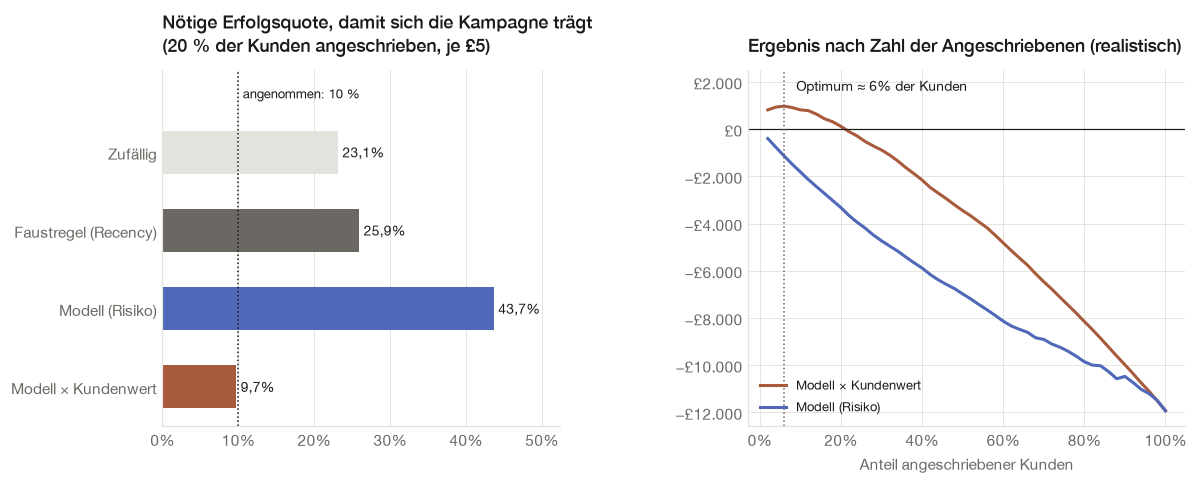

In [29]:
def euro_achse(v: float, _pos: int | None = None) -> str:
    return ("−" if v < 0 else "") + pfund(abs(v))


fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.45, "width_ratios": [1, 1.1]})
be = basis["break_even_quote"]
farben = [F["linie"], F["gedaempft"], F["blau"], F["ziegel"]]
a1.barh(be.index, be.values, color=farben, height=0.55)
a1.axvline(a_real.erfolgsquote, color=F["tinte"], linewidth=1, linestyle=":")
a1.text(a_real.erfolgsquote + 0.006, -0.75, "angenommen: 10 %", fontsize=8.5, va="center")
for i, v in enumerate(be.values):
    a1.text(v + 0.006, i, f"{v:.1%}".replace(".", ","), va="center", fontsize=9)
a1.set_ylim(len(be) - 0.5, -1.05)
a1.grid(axis="y", visible=False)
a1.set_xlim(0, be.max() * 1.2)
a1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.set_title("Nötige Erfolgsquote, damit sich die Kampagne trägt\n(20 % der Kunden angeschrieben, je £5)")

anteile = np.linspace(0.02, 1.0, 50)
ew = test_b["risiko"].to_numpy() * wert
kurve = {
    "Modell × Kundenwert": [kampagnenwert(top_anteil(ew, q), churn_test, wert, a_real)["ergebnis"] for q in anteile],
    "Modell (Risiko)": [kampagnenwert(top_anteil(test_b["risiko"].to_numpy(), q), churn_test, wert, a_real)["ergebnis"]
                        for q in anteile],
}
a2.plot(anteile, kurve["Modell × Kundenwert"], color=F["ziegel"], label="Modell × Kundenwert")
a2.plot(anteile, kurve["Modell (Risiko)"], color=F["blau"], label="Modell (Risiko)")
a2.axhline(0, color=F["tinte"], linewidth=0.8)
q_best = anteile[int(np.argmax(kurve["Modell × Kundenwert"]))]
a2.axvline(q_best, color=F["gedaempft"], linestyle=":", linewidth=1)
a2.annotate(f"Optimum ≈ {q_best:.0%} der Kunden", (q_best, max(kurve["Modell × Kundenwert"])),
            textcoords="offset points", xytext=(8, 10), fontsize=9)
a2.set_ylim(None, 2500)
a2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a2.yaxis.set_major_formatter(FuncFormatter(euro_achse))
a2.set_xlabel("Anteil angeschriebener Kunden")
a2.legend(loc="lower left", fontsize=8.5)
a2.set_title("Ergebnis nach Zahl der Angeschriebenen (realistisch)")
speichern(fig, "11-kampagne")
plt.show()

In [30]:
bester = kampagnenwert(top_anteil(ew, q_best), churn_test, wert, a_real)
print(f"Optimum Modell × Kundenwert: {q_best:.0%} der Kunden = {bester['angeschrieben']} angeschrieben, "
      f"davon {bester['davon_abwanderer']} echte Abwanderer, Ergebnis {pfund(bester['ergebnis'])}, "
      f"ROI {bester['roi']:.0%}")
ERGEBNISSE["kampagne"] = {
    "annahmen": {a.name: vars(a) for a in SZENARIEN},
    "ergebnis_20_prozent": {s: {sz: round(float(v)) for sz, v in z.items()} for s, z in pivot.to_dict("index").items()},
    "trefferquote_20_prozent": {s: round(float(v), 3) for s, v in basis["trefferquote"].items()},
    "erreichter_quartalswert_20_prozent": {s: round(float(v)) for s, v in basis["erreichter_wert"].items()},
    "break_even_quote_20_prozent": {s: round(float(v), 3) for s, v in basis["break_even_quote"].items()},
    "optimum_realistisch": {"anteil": round(float(q_best), 2), **{k: (round(v, 2) if isinstance(v, float) else v)
                                                                  for k, v in bester.items()}},
}

Optimum Modell × Kundenwert: 6% der Kunden = 258 angeschrieben, davon 101 echte Abwanderer, Ergebnis £979, ROI 76%


**Ergebnis der Kampagnenrechnung**

- **Ehrliches Gesamtbild: Eine breite Rückgewinnungskampagne lohnt sich kaum.** Im realistischen Szenario verlieren
  drei von vier Strategien Geld, im pessimistischen alle. Der Grund: Die meisten Abwanderer sind kleine Kunden. Ein
  Gelegenheitskunde mit £60 Quartalsumsatz bringt bei 25 % Marge £15 Deckungsbeitrag, wenn er zurückkommt. Bei 10 %
  Erfolgsquote sind das £1,50 je Kontakt, der Kontakt kostet £5.
- **Risiko allein ist das falsche Kriterium.** Das Modell nach reinem Risiko trifft die meisten echten Abwanderer
  (76 %), aber es sind fast nur kleine Kunden: Es erreicht nur £39k Quartalsumsatz und bräuchte eine Erfolgsquote von
  44 %, um sich zu tragen. Das schlechteste Ergebnis von allen.
- **Risiko × Kundenwert dreht das Bild.** Die Auswahl nach *erwartetem Verlust* trifft zwar weniger Abwanderer
  (41 %), dafür die wertvollen: £177k Quartalsumsatz. Damit trägt sich die Kampagne schon ab rund 10 % Erfolgsquote,
  und im optimistischen Szenario bringt sie £13k.
- **Weniger ist mehr.** Das Optimum liegt bei den 6 % Kunden mit dem höchsten erwarteten Verlust (258 Kunden):
  rund £1.000 Ergebnis bei 76 % ROI im realistischen Szenario. Jeder weitere Kontakt kostet £5, bringt aber im
  Schnitt immer weniger.

Für das Marketing heißt das: **kein Gießkannen-Gutschein, sondern eine kleine, persönliche Aktion** für ein paar
hundert wertvolle, gefährdete Kunden. Für diese Gruppe lohnt sich auch ein teurerer Kanal (Anruf des
Außendienstes), denn ihr Deckungsbeitrag ist hoch genug.

**Was diese Rechnung nicht kann:** Die Erfolgsquote ist eine Annahme, nicht gemessen. Bevor man das Budget
freigibt, gehört die Kampagne in einen **A/B-Test mit Kontrollgruppe** (z. B. 80 % der Auswahl anschreiben,
20 % nicht). Erst der Unterschied zwischen beiden Gruppen zeigt die echte Wirkung (Uplift).

## 6 · Fazit

1. **Bereinigung:** Von 1,07 Mio. Zeilen bleiben 770.398 Verkaufszeilen von 5.839 identifizierten Kunden. Jeder
   Schritt ist begründet; der größte Einschnitt (fehlende Kunden-ID, 15 % des Umsatzes) ist als Grenze benannt.
2. **Segmente:** Vier gut interpretierbare Segmente. 20 % Top-Kunden bringen 73 % des Umsatzes; die
   „gefährdeten Stammkunden“ sind mit 17 % Umsatzanteil der Hebel für Rückgewinnung.
3. **Churn:** Mit sauberem Stichtag-Design und Out-of-Time-Test erreicht die Logistic Regression ROC-AUC 0,77
   (Faustregel 0,71, CV auf dem Trainings-Stichtag 0,81). Komplexere Modelle bringen hier keinen Mehrwert.
4. **Business:** Eine breite Rückgewinnungskampagne rechnet sich unter vorsichtigen Annahmen nicht. Mit
   wertbasierter Auswahl (Risiko × Kundenwert) trägt sie sich ab ~10 % Erfolgsquote; das Optimum ist eine kleine,
   gezielte Aktion für ~260 Kunden. Vor dem Rollout: A/B-Test mit Kontrollgruppe.

In [31]:
(K.PROJEKT / "eval").mkdir(exist_ok=True)
with open(K.PROJEKT / "eval" / "ergebnisse.json", "w", encoding="utf-8") as f:
    json.dump(ERGEBNISSE, f, ensure_ascii=False, indent=2, default=str)
print("Kennzahlen gespeichert in eval/ergebnisse.json")

Kennzahlen gespeichert in eval/ergebnisse.json
